# Layer fidelity: how good is a whole line of qubits?

## The problem

The randomized benchmarking notebook measured the error of the gates on one qubit. A real circuit does more. It uses many qubits, it runs gates on several of them at once, and its two-qubit gates are about ten times worse than its one-qubit gates. A device with excellent one-qubit gates can still be a poor machine for circuits that entangle qubits.

We want one number that says how well a chain of $N$ qubits works when it is used this way. The number is the **layer fidelity**, and the idea is the one from randomized benchmarking applied to every link of the chain.

A **link** is a pair of neighboring qubits that a two-qubit gate can act on. A chain of $N$ qubits has $N-1$ links.

1. **Split the links into layers.** A layer is a set of two-qubit gates that run at the same time. Two links that share a qubit cannot be in the same layer, so a chain needs two: the even links (0-1, 2-3, ...) and the odd links (1-2, 3-4, ...).
2. **Run randomized benchmarking on every link of a layer simultaneously**, each with its own random two-qubit gates. Running them together includes the interference between neighbors, which a test of one link alone leaves out.
3. **Fit the decay of each link** and convert its decay rate to a fidelity, a number between 0 and 1 where 1 is a perfect gate (Step 1 gives the formula).
4. **Multiply the $N-1$ process fidelities.** The product is the layer fidelity.

A single number for a chain would hide a weak link, so the notebook also shows the fidelity of each link.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | The layers, the decay model of a pair, and the layer fidelity | `ops.py` |
| 2. Encoding | Put one random sequence for each link of a layer into one circuit | `encoding.py` |
| 3. Execution | Run every layer, length, and random draw as one job | `execution.py` |
| 4. Analysis | Fit each link, multiply the fidelities, plot | `analysis.py` |

The same steps run from the command line with `python layer_fidelity/main.py`, started in `../scripts/`.

## Setup

By default this notebook runs on the Aer simulator with a chain of 4 qubits (3 links). Each CX gate has a depolarizing error (with some probability the state is replaced by a random one) that depends on the link: 1.0% on link 0-1, 2.5% on link 1-2, and 1.5% on link 2-3. Read-out has a 2-4% error. Because we know the noise we put in, we can check the answer. To measure a real chain, set `backend_name = "ibm_rensselaer"` and give `chain`, the physical qubits in order. Each consecutive pair must be connected on the device.

- `n_qubits`: chain length on the simulator. On hardware it is the length of `chain`.
- `lengths`: numbers of two-qubit Cliffords per sequence. The longest should let the survival fall most of the way to its floor of 0.25.
- `sequences`: random sequences per length and link.
- `shots`: repetitions of each circuit.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Operator

# The layer fidelity code lives in ../scripts/layer_fidelity.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/layer_fidelity").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
chain = None  # physical qubits in order on hardware, e.g. [0, 1, 2, 3]
n_qubits = 4 if chain is None else len(chain)
lengths = ops.LENGTHS
sequences = 20
shots = 500
seed = 1

## Step 1: The operator (layers and fidelities)

### The layers

`link_layers` splits the links of a chain into the two layers. For 4 qubits the even layer runs links 0-1 and 2-3 together, and the odd layer runs link 1-2 alone. For 6 qubits the odd layer has two links.

In [2]:
for n in (4, 6):
    print(f"{n} qubits:", ops.link_layers(n))

4 qubits: [[(0, 1), (2, 3)], [(1, 2)]]
6 qubits: [[(0, 1), (2, 3), (4, 5)], [(1, 2), (3, 4)]]


### Randomized benchmarking of a pair

For one qubit the survival probability after $m$ random Cliffords was $A\,p^m + B$ with a floor near $\tfrac12$. For a pair of qubits there are four outcomes (00, 01, 10, 11), and a random guess gives 00 one time in four, so the floor is near $\tfrac14$. We define the **survival probability** of a link as the fraction of shots in which both qubits read 0, and fit

$$F(m) = A\,p^m + B, \qquad B \approx \tfrac14 \text{ in the ideal case.}$$

The two-qubit Cliffords are a set of 11,520 gates. We do not list them. Qiskit draws one at random with `random_clifford(2)` and writes it as a circuit of CX, $H$, and $S$ gates. As for one qubit, a sequence of Cliffords is again a Clifford, so the last gate, the inverse of all the others, comes from the same set.

### From the decay rate to the process fidelity

As before, each Clifford keeps the state with probability $p$ and replaces it with a random one with probability $1-p$. A pair has $d = 4$ outcomes, and the chance that a random state is right is $1/d^2 = 1/16$. The **process fidelity** of the link is therefore

$$\mathrm{PF} = p + \frac{1-p}{16}.$$

### The layer fidelity

The **layer fidelity** is the product of the process fidelities of all the links,

$$\mathrm{LF} = \mathrm{PF}_1\,\mathrm{PF}_2\cdots\mathrm{PF}_{N-1}.$$

It falls as the chain gets longer, which makes chains of different lengths hard to compare. The **error per layered gate** divides that out:

$$\mathrm{EPLG} = \tfrac45\left(1 - \mathrm{LF}^{1/(N-1)}\right).$$

$\mathrm{LF}^{1/(N-1)}$ is the **geometric mean** of the link fidelities (the $(N-1)$th root of their product). It is the fidelity of a typical link, and one minus it is the error of a typical link. The factor $4/5 = d/(d+1)$ converts a process error into the error of an average gate, the number a single gate is quoted with.

**Worked example.** Three links have process fidelities 0.99, 0.97, and 0.98.

1. Multiply: $\mathrm{LF} = 0.99 \times 0.97 \times 0.98 = 0.9411$.
2. Take the geometric mean: $0.9411^{1/3} = 0.9800$.
3. Convert: $\mathrm{EPLG} = \tfrac45(1 - 0.9800) = 0.0160$.

**Check.** The simple mean of the three fidelities is $0.9800$. The geometric mean is never larger than the simple mean, and for numbers this close together the two agree to four digits, so $0.9800$ is consistent.

In [3]:
pf = [0.99, 0.97, 0.98]
lf = ops.layer_fidelity(pf)
print(f"LF = {lf:.4f}")
print(f"geometric mean = {lf ** (1 / 3):.4f}")
print(f"EPLG = {ops.eplg(lf, 3):.4f}")

LF = 0.9411
geometric mean = 0.9800
EPLG = 0.0160


**Stop and think.**

1. **One weak link lowers the whole product.** Because the fidelities multiply, one link at 0.90 and two at 0.99 give $\mathrm{LF} = 0.882$. Three links at 0.959 give the same LF. Which is the better chain for a circuit that uses only the two good links, and what does the layer fidelity not tell you?
2. **Two layers are enough for any chain.** Every qubit has at most two neighbors, so alternating links (even, odd) never share a qubit. A grid of qubits needs more layers.
3. **Run the layer, not the link.** The simulator in this notebook has no interference between links, so running them together or alone gives the same result. On hardware, neighboring gates disturb each other (crosstalk), and the layer measurement is built to see this.

## Step 2: Encoding (one layer circuit)

For every link in the layer we draw a random sequence of $m$ two-qubit Cliffords plus the inverse, and place them on the qubits of the link. All the links of the layer share one circuit, so they run at the same time. A barrier after each Clifford keeps the compiler from merging neighbors. A qubit that is in no link of the layer does nothing.

layer: [(0, 1), (2, 3)]


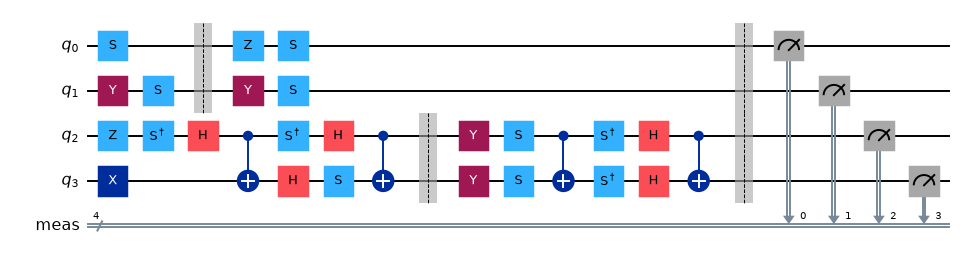

In [4]:
rng = np.random.default_rng(seed)
layer = ops.link_layers(4)[0]  # links 0-1 and 2-3
print("layer:", layer)

circuit = enc.build_layer_circuit(layer, 4, 1, rng)  # one random Clifford per link
display(circuit.draw("mpl", fold=40, scale=0.7))
plt.close()

Check that one pair's sequence is the identity. We build a sequence of 5 random Cliffords with its inverse and compare its unitary matrix with the identity.

In [5]:
sequence = ops.pair_sequence(5, rng)
print("equals the identity (up to a global phase):", Operator(sequence).equiv(Operator(np.eye(4))))
print("gates in the circuit:", dict(sequence.count_ops()))

equals the identity (up to a global phase): True
gates in the circuit: {'h': 24, 'sdg': 13, 'cx': 12, 's': 11, 'x': 5, 'barrier': 5, 'y': 3, 'z': 1}


The circuit contains CX gates and one-qubit gates. Before running, `transpile_for` rewrites everything in the gates the device supports, with the optimizer **off**, because every sequence is the identity and an optimizer would delete it. We count the CX gates in the compiled circuits, since they carry almost all of the error.

## Step 3: Execution

There are 2 layers, 9 lengths, and 20 sequences per length, so $2 \times 9 \times 20 = 360$ circuits. They go out as **one job**, since on hardware the queue wait is paid per job.

On the simulator each CX has a depolarizing error that depends on its link, and read-out has an error. The decay rate of each link then follows from the numbers. An error $e$ on a CX multiplies the signal by $(1-e)$, and it does so alike for all the errors a pair can have, so a Clifford with $k$ CX gates multiplies it by $(1-e)^k$. The built-in $p$ is the average of that over random Cliffords.

In [6]:
data = execution.run(n_qubits, lengths, sequences, shots, backend_name, chain, seed)

print(f"{data['seconds']:.1f} s")
print(f"CX gates per two-qubit Clifford: {data['cx_per_clifford']:.2f}")
print("layers:", data["layers"])

3.5 s
CX gates per two-qubit Clifford: 1.50
layers: [[[0, 1], [2, 3]], [[1, 2]]]


## Step 4: Analysis

### Fit every link

For each link we average the survival probability over the sequences of each length and fit $A\,p^m + B$, as in the randomized benchmarking notebook. The first figure shows one panel per link. Gray dots are single sequences and colored dots are their means. The curves that fall faster belong to the links with the larger error.

link             decay rate p       process fidelity  built in
0-1           0.9841 +/- 0.0016      0.9851 +/- 0.0015    0.9857
1-2           0.9626 +/- 0.0009      0.9649 +/- 0.0008    0.9644
2-3           0.9781 +/- 0.0019      0.9795 +/- 0.0018    0.9786

layer fidelity LF = 0.9310 +/- 0.0023   (built in: 0.9302)
EPLG              = 0.0188 +/- 0.0007   (built in: 0.0191)


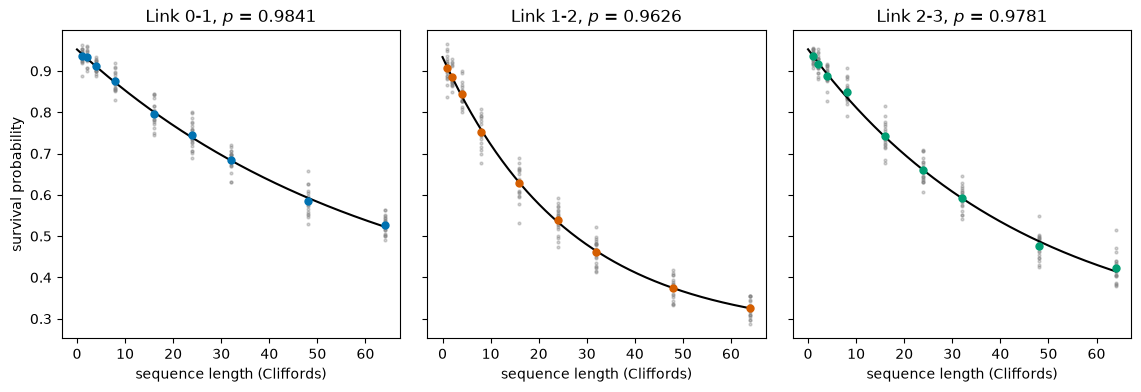

In [7]:
result = analysis.fit_layer(data)
analysis.print_table(data, result)

fig = analysis.plot_links(data, result)
display(fig)
plt.close(fig)

The table gives, for each link, the decay rate $p$ and the process fidelity, with their standard errors. On the simulator it also shows the value built into the noise model. The layer fidelity and the error per layered gate come below it. Their errors come from the link errors, which are independent, so the relative errors add in quadrature.

### Process fidelity of each link and the layer fidelity

The left panel shows the process fidelity of each link. The right panel shows the layer fidelity of the first $k$ links, which is how the fidelity falls as the chain grows.

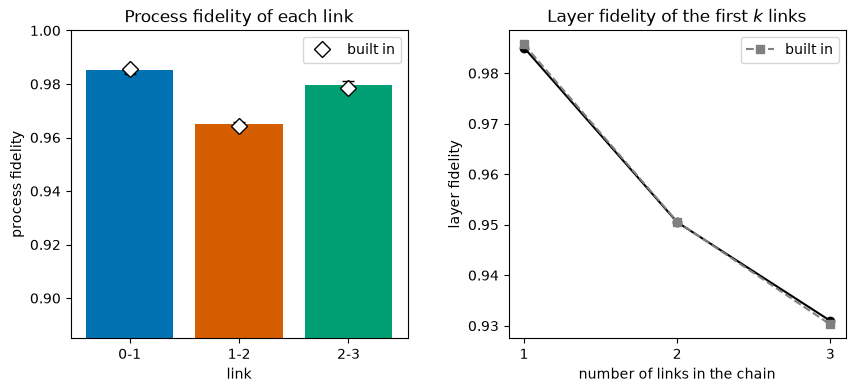

LF   = 0.9310 +/- 0.0023
EPLG = 0.0188 +/- 0.0007


In [8]:
fig = analysis.plot_layer(data, result)
display(fig)
plt.close(fig)

print(f"LF   = {result['lf']:.4f} +/- {result['lf_error']:.4f}")
print(f"EPLG = {result['eplg']:.4f} +/- {result['eplg_error']:.4f}")

**Stop and think.** Link 1-2 has the largest error, and the layer fidelity of the first two links drops the most. What would the layer fidelity of the chain be if we replaced link 1-2 with a link as good as 0-1? Use the process fidelities from the table.

In [9]:
pfs = {name: link["pf"] for name, link in result["links"].items()}
best = max(pfs.values())
improved = ops.layer_fidelity([best if name == "1-2" else pf for name, pf in pfs.items()])
print(f"LF now: {result['lf']:.4f}")
print(f"LF with link 1-2 as good as the best link: {improved:.4f}")

LF now: 0.9310
LF with link 1-2 as good as the best link: 0.9504


## Reading the results

- **The fit recovers the built-in fidelities.** Each link's process fidelity lies within a few standard errors of its built-in value, and so does the layer fidelity. Reruns with another `seed` move the numbers by about their error bars.
- **The layer fidelity is dominated by the weakest links.** Link 1-2 has a CX error 2.5 times that of link 0-1, so it costs about 2.5 times as much of the layer fidelity. A weak link is visible in the left panel and invisible in a single product, which is why both are reported.
- **EPLG lets chains of different lengths be compared.** A chain of 20 qubits has a smaller layer fidelity than one of 4 even if every link is the same. EPLG is that common link error.
- **Simplifications.** The definition used by IBM runs additional one-qubit RB on the idle qubits and handles the links between two gates of a layer in a more careful way. The notebook uses the principle (benchmark all links of a layer together, multiply) and leaves out these details.

On hardware, expect a smaller fidelity than the one on the calibration page for the same link, because the layer measurement includes crosstalk. Expect also that the weakest link is not the same on every day. Gate errors drift, and the first thing to look at when a layer fidelity falls is which link moved.

## What to try next

1. Change `SIM_LINK_ERROR` in `ops.py` to `(0.01, 0.01, 0.01)`. All links are alike now. Predict the layer fidelity and run it.
2. Set `n_qubits = 6` and rerun. How does the layer fidelity change, and how does EPLG? Which of the two is a property of the chain, and which of the number of links?
3. Run `execution.run(..., simultaneous=False)` so each link runs alone. Do the fidelities change on the simulator? What would you expect on hardware, and why?
4. Change `lengths` to `(1, 2, 4, 8)`. What happens to the error of $p$, and to the fidelity?
5. Increase `sequences` to 50. How much does the error of the layer fidelity shrink?
6. Replace the error of the middle link with `0.005` and `0.05`. How much does the layer fidelity depend on a single link?
7. Run on `ibm_rensselaer` with `chain = [0, 1, 2, 3]` (check the coupling map first), then with another chain. Which chain has the better layer fidelity?